# Practical Assignment 4: Classification Models
# Rice Classification — SVM, Decision Tree, KNN and Naïve Bayes

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load Dataset

In [4]:
DATA_PATH = "riceClassification.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (18185, 12)


,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


## 2. Dataset Overview

In [7]:
print("Columns:", df.columns.tolist())
df.info()

print("\\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))

print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

if "Class" not in df.columns:
    raise ValueError("Target column 'Class' was not found.")
display(df["Class"].value_counts(dropna=False).sort_index().to_frame("Class count"))

Columns: ['id', 'Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation', 'Class']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               18185 non-null  int64  
 1   Area             18185 non-null  int64  
 2   MajorAxisLength  18185 non-null  float64
 3   MinorAxisLength  18185 non-null  float64
 4   Eccentricity     18185 non-null  float64
 5   ConvexArea       18185 non-null  int64  
 6   EquivDiameter    18185 non-null  float64
 7   Extent           18185 non-null  float64
 8   Perimeter        18185 non-null  float64
 9   Roundness        18185 non-null  float64
 10  AspectRation     18185 non-null  float64
 11  Class            18185 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 1.7 MB
\nMissing values:


,Missing values
id,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Perimeter,0
Roundness,0


\nDuplicate rows: 0
\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
id,18185.0,9093.000000,5249.701658,1.000000,4547.000000,9093.000000,13639.000000,18185.000000
Area,18185.0,7036.492989,1467.197150,2522.000000,5962.000000,6660.000000,8423.000000,10210.000000
MajorAxisLength,18185.0,151.680754,12.376402,74.133114,145.675910,153.883750,160.056214,183.211434
MinorAxisLength,18185.0,59.807851,10.061653,34.409894,51.393151,55.724288,70.156593,82.550762
Eccentricity,18185.0,0.915406,0.030575,0.676647,0.891617,0.923259,0.941372,0.966774
ConvexArea,18185.0,7225.817872,1502.006571,2579.000000,6125.000000,6843.000000,8645.000000,11008.000000
EquivDiameter,18185.0,94.132952,9.906250,56.666658,87.126656,92.085696,103.559146,114.016559
Extent,18185.0,0.616653,0.104389,0.383239,0.538530,0.601194,0.695664,0.886573
Perimeter,18185.0,351.606949,29.500620,197.015000,333.990000,353.088000,373.003000,508.511000
Roundness,18185.0,0.707998,0.067310,0.174590,0.650962,0.701941,0.769280,0.904748


,Class count
Class,
0,8200
1,9985


## 3. Clean Dataset

In [10]:
data = df.drop_duplicates().copy()
data = data.dropna(subset=["Class"]).copy()

X = data.drop(columns=["Class"] + (["id"] if "id" in data.columns else [])).copy()
X = X.apply(pd.to_numeric, errors="coerce")
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    X = X.drop(columns=all_missing)

if X.shape[1] == 0:
    raise ValueError("No usable numeric feature columns found.")

y_raw = data["Class"].copy()
label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(y_raw.astype(str)), index=y_raw.index, name="Class")

print("Shape after duplicate/target cleaning:", data.shape)
print("Feature columns:", X.columns.tolist())
print("Target labels:", list(label_encoder.classes_))
print("Missing feature values to be imputed inside pipelines:", int(X.isna().sum().sum()))

Shape after duplicate/target cleaning: (18185, 12)
Feature columns: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation']
Target labels: ['0', '1']
Missing feature values to be imputed inside pipelines: 0


## 4. Statistical Analysis

In [13]:
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
Area,18185.0,7036.492989,1467.197150,2522.000000,5962.000000,6660.000000,8423.000000,10210.000000
MajorAxisLength,18185.0,151.680754,12.376402,74.133114,145.675910,153.883750,160.056214,183.211434
MinorAxisLength,18185.0,59.807851,10.061653,34.409894,51.393151,55.724288,70.156593,82.550762
Eccentricity,18185.0,0.915406,0.030575,0.676647,0.891617,0.923259,0.941372,0.966774
ConvexArea,18185.0,7225.817872,1502.006571,2579.000000,6125.000000,6843.000000,8645.000000,11008.000000
EquivDiameter,18185.0,94.132952,9.906250,56.666658,87.126656,92.085696,103.559146,114.016559
Extent,18185.0,0.616653,0.104389,0.383239,0.538530,0.601194,0.695664,0.886573
Perimeter,18185.0,351.606949,29.500620,197.015000,333.990000,353.088000,373.003000,508.511000
Roundness,18185.0,0.707998,0.067310,0.174590,0.650962,0.701941,0.769280,0.904748
AspectRation,18185.0,2.599081,0.434836,1.358128,2.208527,2.602966,2.964101,3.911845


## 5. Class Distribution

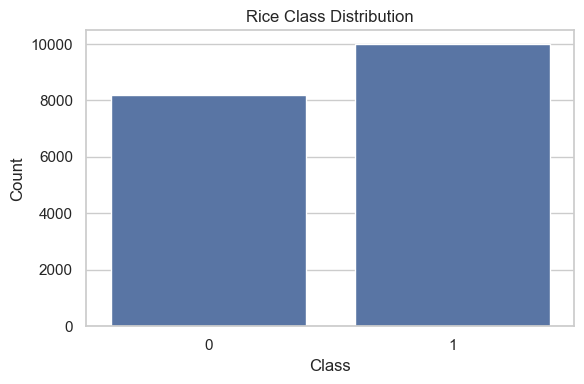

In [16]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_raw.astype(str), order=sorted(y_raw.astype(str).unique()))
plt.title("Rice Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 6. Feature Distribution

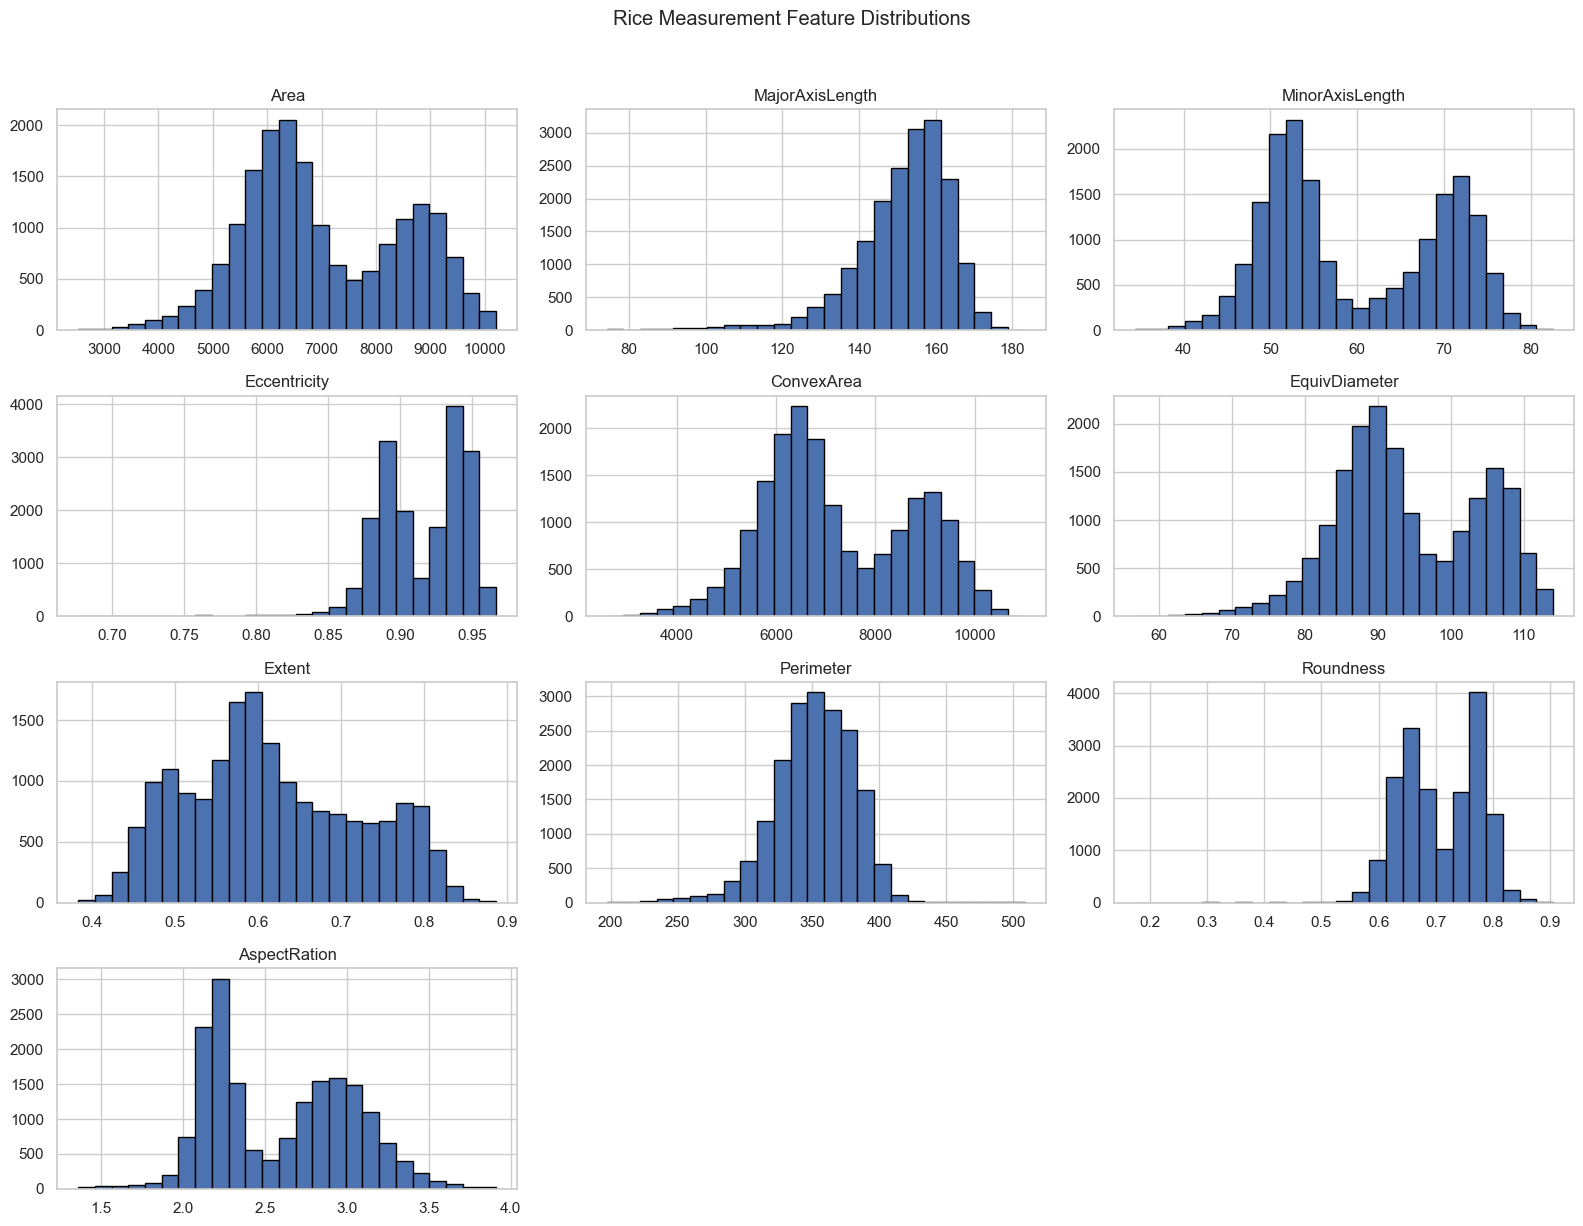

In [18]:
X.hist(figsize=(16, 12), bins=25, edgecolor="black")
plt.suptitle("Rice Measurement Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

## 7. Outlier Detection

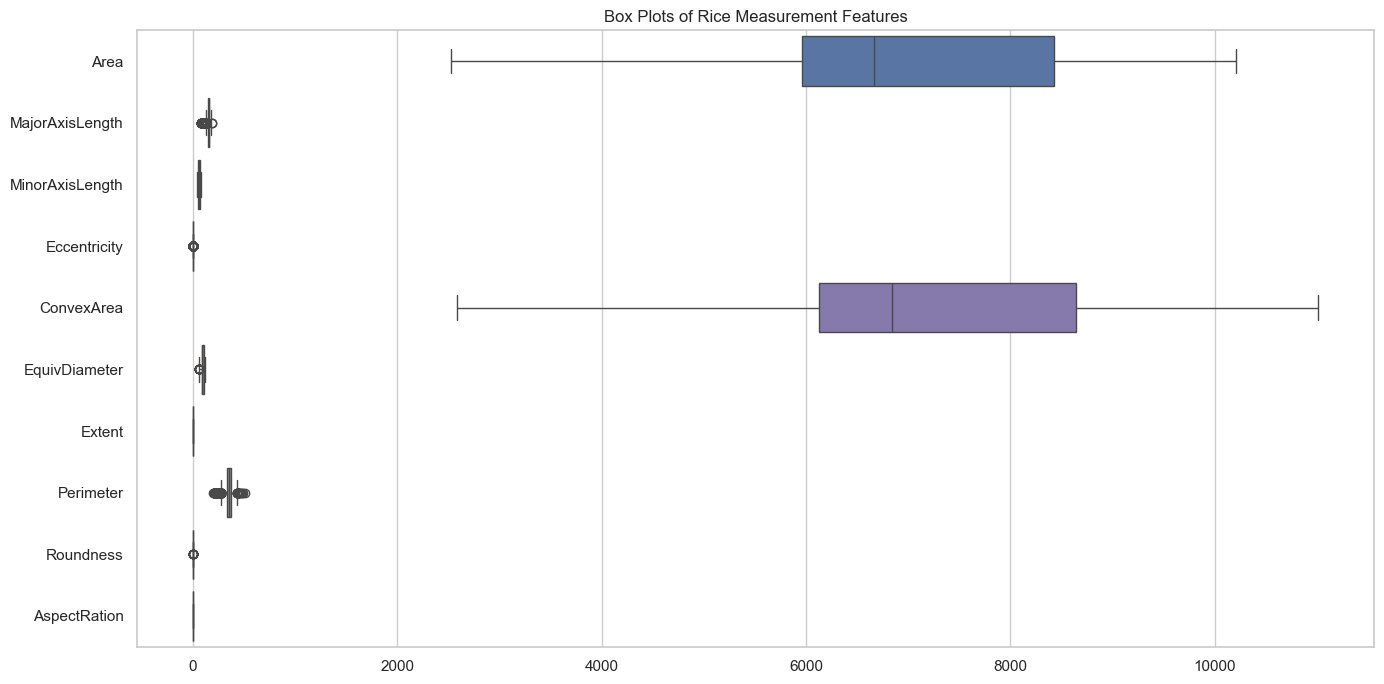

In [21]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=X, orient="h")
plt.title("Box Plots of Rice Measurement Features")
plt.tight_layout()
plt.show()

## 8. Correlation Heatmap

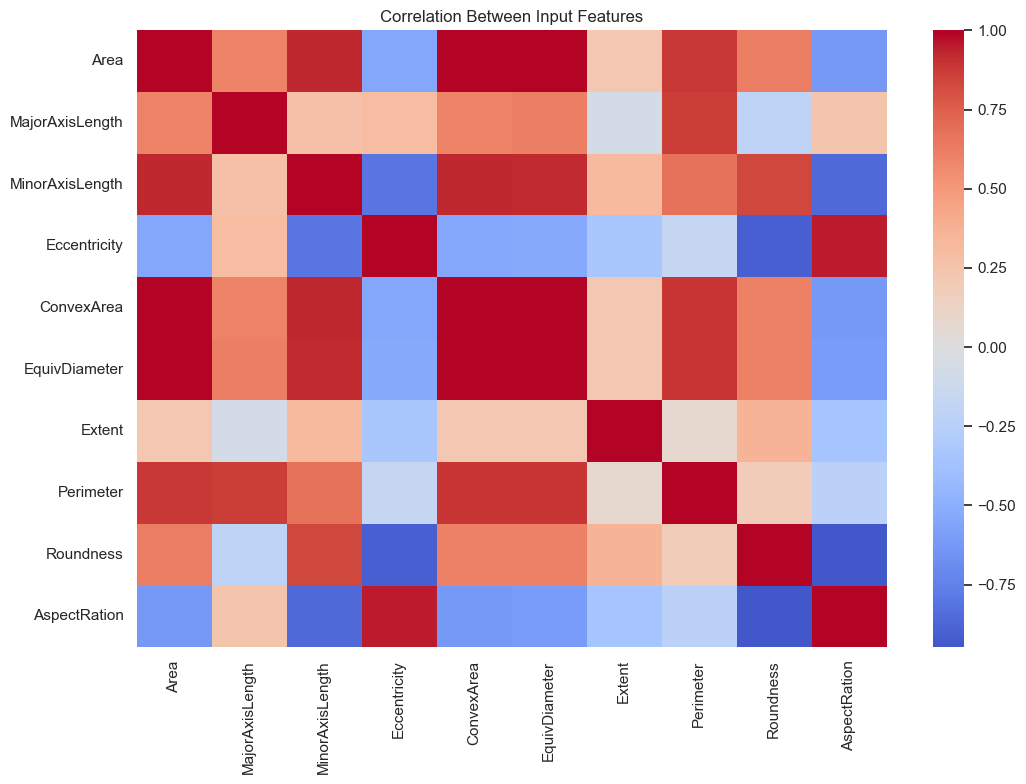

In [23]:
plt.figure(figsize=(11, 8))
sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Between Input Features")
plt.tight_layout()
plt.show()

## 9. Train-Test Split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("Proportion"))
print("\\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("Proportion"))

Training samples: 14548
Testing samples: 3637
\nTraining class proportions:


,Proportion
Class,
0,0.450921
1,0.549079


\nTesting class proportions:


,Proportion
Class,
0,0.450921
1,0.549079


## 10. Create Classification Pipelines

In [27]:
models = {
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naïve Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ])
}

## 11. Tune KNN Hyperparameters

In [29]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier())
])

knn_grid_params = {
    "classifier__n_neighbors": [3, 5, 7, 9],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
knn_search = GridSearchCV(
    knn_pipeline, knn_grid_params, scoring="accuracy",
    cv=cv, n_jobs=-1, refit=True
)
knn_search.fit(X_train, y_train)
models["KNN"] = knn_search.best_estimator_
print("Best KNN parameters:", knn_search.best_params_)
print("Best KNN CV accuracy:", round(knn_search.best_score_, 4))

Best KNN parameters: {'classifier__n_neighbors': 9, 'classifier__p': 1, 'classifier__weights': 'uniform'}
Best KNN CV accuracy: 0.988


### KNN — Confusion Matrix

KNN Accuracy: 0.9915
KNN Precision (macro): 0.9915
KNN Recall (macro): 0.9913
KNN F1-score (macro): 0.9914


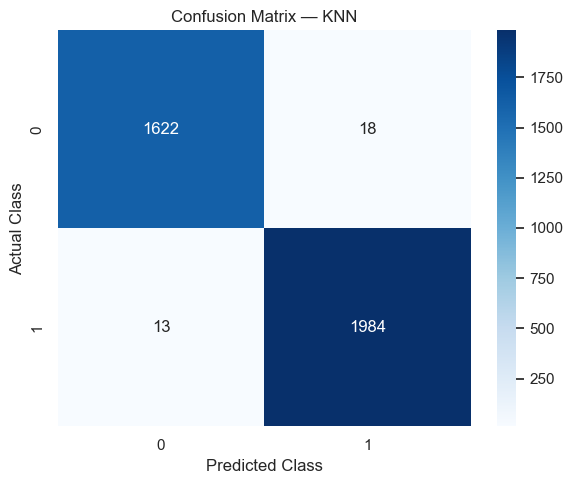

In [31]:
class_names = [str(v) for v in label_encoder.classes_]
knn_pred_intermediate = models["KNN"].predict(X_test)
knn_cm_intermediate = confusion_matrix(y_test, knn_pred_intermediate, labels=np.arange(len(class_names)))

print("KNN Accuracy:", round(accuracy_score(y_test, knn_pred_intermediate), 4))
print("KNN Precision (macro):", round(precision_score(y_test, knn_pred_intermediate, average="macro", zero_division=0), 4))
print("KNN Recall (macro):", round(recall_score(y_test, knn_pred_intermediate, average="macro", zero_division=0), 4))
print("KNN F1-score (macro):", round(f1_score(y_test, knn_pred_intermediate, average="macro", zero_division=0), 4))

plt.figure(figsize=(6, 5))
sns.heatmap(knn_cm_intermediate, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix — KNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

## 12. Tune SVM Hyperparameters

In [33]:
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(probability=True, random_state=RANDOM_STATE))
])

svm_grid_params = {
    "classifier__C": [0.1, 1, 10],
    "classifier__kernel": ["linear", "rbf"]
}
svm_search = GridSearchCV(
    svm_pipeline, svm_grid_params, scoring="accuracy",
    cv=cv, n_jobs=-1, refit=True
)
svm_search.fit(X_train, y_train)
models["SVM"] = svm_search.best_estimator_
print("Best SVM parameters:", svm_search.best_params_)
print("Best SVM CV accuracy:", round(svm_search.best_score_, 4))

Best SVM parameters: {'classifier__C': 1, 'classifier__kernel': 'rbf'}
Best SVM CV accuracy: 0.9897


### SVM — Confusion Matrix

SVM Accuracy: 0.9926
SVM Precision (macro): 0.9928
SVM Recall (macro): 0.9923
SVM F1-score (macro): 0.9925


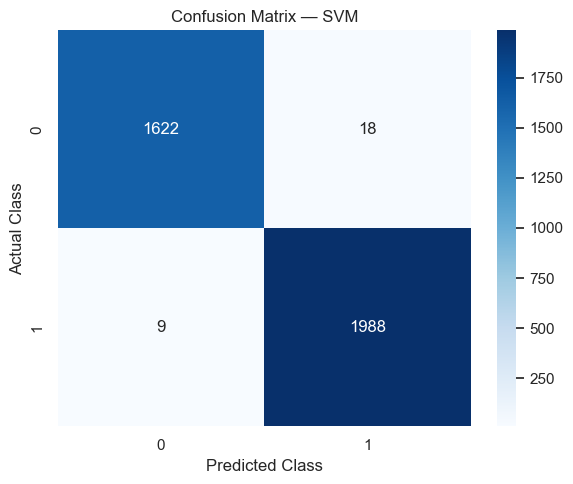

In [35]:
svm_pred_intermediate = models["SVM"].predict(X_test)
svm_cm_intermediate = confusion_matrix(y_test, svm_pred_intermediate, labels=np.arange(len(class_names)))

print("SVM Accuracy:", round(accuracy_score(y_test, svm_pred_intermediate), 4))
print("SVM Precision (macro):", round(precision_score(y_test, svm_pred_intermediate, average="macro", zero_division=0), 4))
print("SVM Recall (macro):", round(recall_score(y_test, svm_pred_intermediate, average="macro", zero_division=0), 4))
print("SVM F1-score (macro):", round(f1_score(y_test, svm_pred_intermediate, average="macro", zero_division=0), 4))

plt.figure(figsize=(6, 5))
sns.heatmap(svm_cm_intermediate, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix — SVM")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

## 13. Train Decision Tree and Naïve Bayes

In [37]:
models["Decision Tree"].fit(X_train, y_train)
models["Naïve Bayes"].fit(X_train, y_train)
print("All four models are ready for evaluation.")

All four models are ready for evaluation.


### Decision Tree — Confusion Matrix

Decision Tree Accuracy: 0.9843
Decision Tree Precision (macro): 0.9841
Decision Tree Recall (macro): 0.9843
Decision Tree F1-score (macro): 0.9842


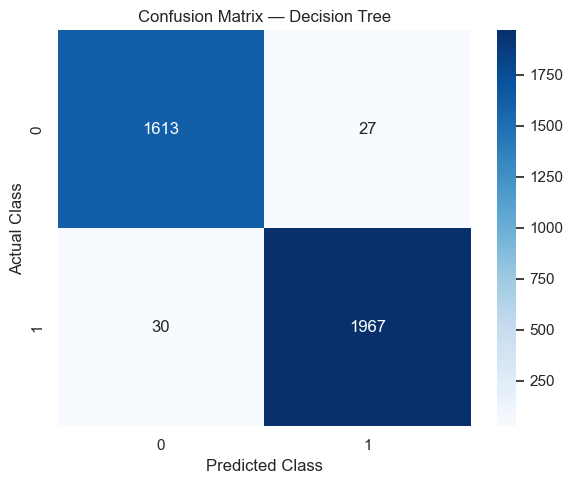

In [39]:
dt_pred_intermediate = models["Decision Tree"].predict(X_test)
dt_cm_intermediate = confusion_matrix(y_test, dt_pred_intermediate, labels=np.arange(len(class_names)))

print("Decision Tree Accuracy:", round(accuracy_score(y_test, dt_pred_intermediate), 4))
print("Decision Tree Precision (macro):", round(precision_score(y_test, dt_pred_intermediate, average="macro", zero_division=0), 4))
print("Decision Tree Recall (macro):", round(recall_score(y_test, dt_pred_intermediate, average="macro", zero_division=0), 4))
print("Decision Tree F1-score (macro):", round(f1_score(y_test, dt_pred_intermediate, average="macro", zero_division=0), 4))

plt.figure(figsize=(6, 5))
sns.heatmap(dt_cm_intermediate, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix — Decision Tree")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Naïve Bayes — Confusion Matrix

Naïve Bayes Accuracy: 0.978
Naïve Bayes Precision (macro): 0.9805
Naïve Bayes Recall (macro): 0.9758
Naïve Bayes F1-score (macro): 0.9777


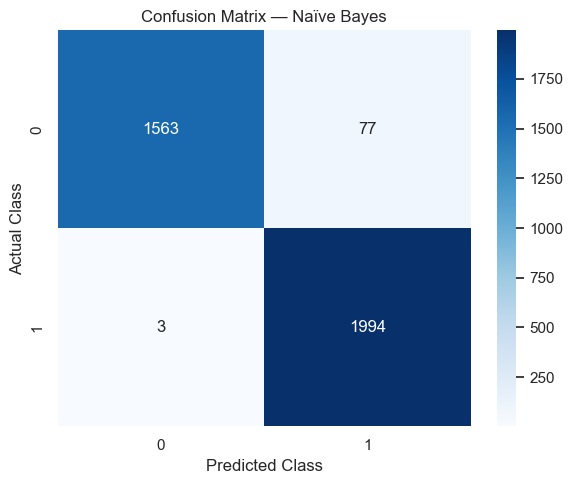

In [42]:
nb_pred_intermediate = models["Naïve Bayes"].predict(X_test)
nb_cm_intermediate = confusion_matrix(y_test, nb_pred_intermediate, labels=np.arange(len(class_names)))

print("Naïve Bayes Accuracy:", round(accuracy_score(y_test, nb_pred_intermediate), 4))
print("Naïve Bayes Precision (macro):", round(precision_score(y_test, nb_pred_intermediate, average="macro", zero_division=0), 4))
print("Naïve Bayes Recall (macro):", round(recall_score(y_test, nb_pred_intermediate, average="macro", zero_division=0), 4))
print("Naïve Bayes F1-score (macro):", round(f1_score(y_test, nb_pred_intermediate, average="macro", zero_division=0), 4))

plt.figure(figsize=(6, 5))
sns.heatmap(nb_cm_intermediate, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix — Naïve Bayes")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

## 14. Evaluate All Models

In [44]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Log Loss": log_loss(y_test, y_prob, labels=np.arange(len(label_encoder.classes_)))
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Log Loss
0,SVM,0.9926,0.9928,0.9923,0.9925,0.0314
1,KNN,0.9915,0.9915,0.9913,0.9914,0.0784
2,Decision Tree,0.9843,0.9841,0.9843,0.9842,0.5649
3,Naïve Bayes,0.9780,0.9805,0.9758,0.9777,0.1493


## 15. Classification Reports

In [50]:
class_names = [str(v) for v in label_encoder.classes_]
for name, y_pred in predictions.items():
    print("\\n" + "=" * 60)
    print(name)
    print(classification_report(
        y_test, y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

\n============================================================
SVM
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1640
           1       0.99      1.00      0.99      1997

    accuracy                           0.99      3637
   macro avg       0.99      0.99      0.99      3637
weighted avg       0.99      0.99      0.99      3637

\n============================================================
Decision Tree
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1640
           1       0.99      0.98      0.99      1997

    accuracy                           0.98      3637
   macro avg       0.98      0.98      0.98      3637
weighted avg       0.98      0.98      0.98      3637

\n============================================================
KNN
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1640
           1       0.99   

## 17. Accuracy, Precision, Recall and F1-score Comparison

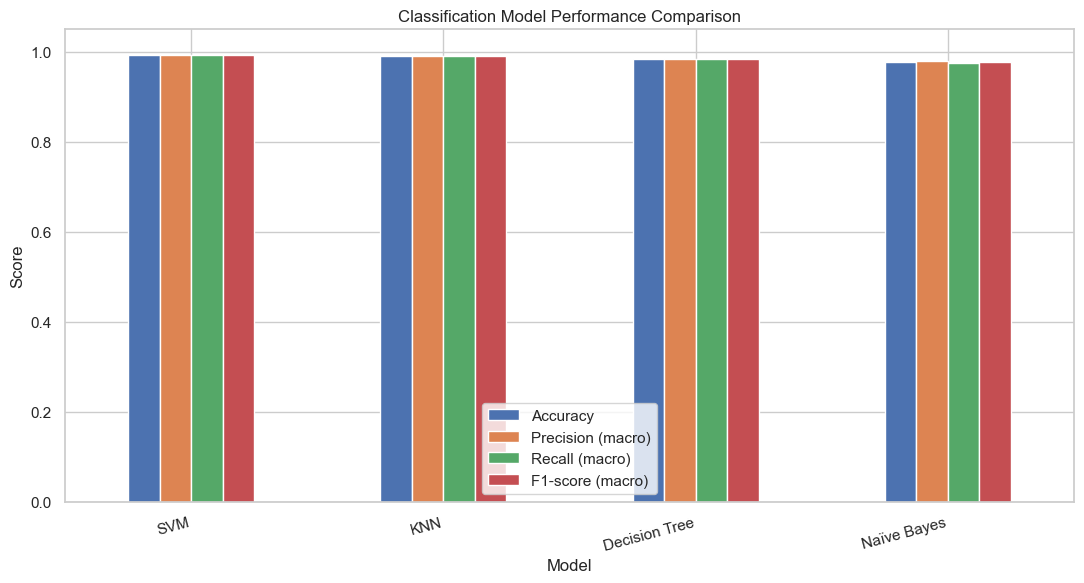

In [52]:
metrics_to_plot = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
ax = results_df.set_index("Model")[metrics_to_plot].plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
ax.set_title("Classification Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 18. Log Loss Comparison

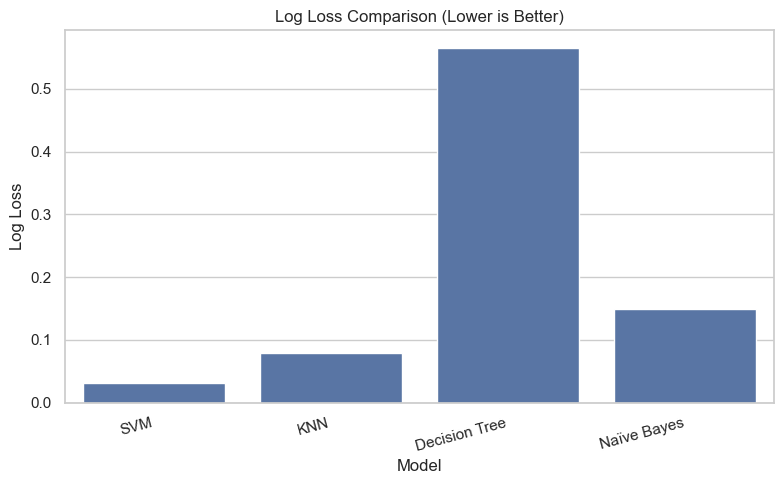

In [54]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="Log Loss")
plt.title("Log Loss Comparison (Lower is Better)")
plt.xlabel("Model")
plt.ylabel("Log Loss")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 19. Cross-Validation Comparison

In [56]:
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_rows.append({
        "Model": name,
        "Mean CV F1 (macro)": scores.mean(),
        "Std CV F1 (macro)": scores.std()
    })
cv_results_df = pd.DataFrame(cv_rows).sort_values("Mean CV F1 (macro)", ascending=False)
display(cv_results_df.round(4))

,Model,Mean CV F1 (macro),Std CV F1 (macro)
0,SVM,0.9896,0.0017
2,KNN,0.9879,0.0009
1,Decision Tree,0.9821,0.0021
3,Naïve Bayes,0.9762,0.0004


## 20. Decision Tree Visualization

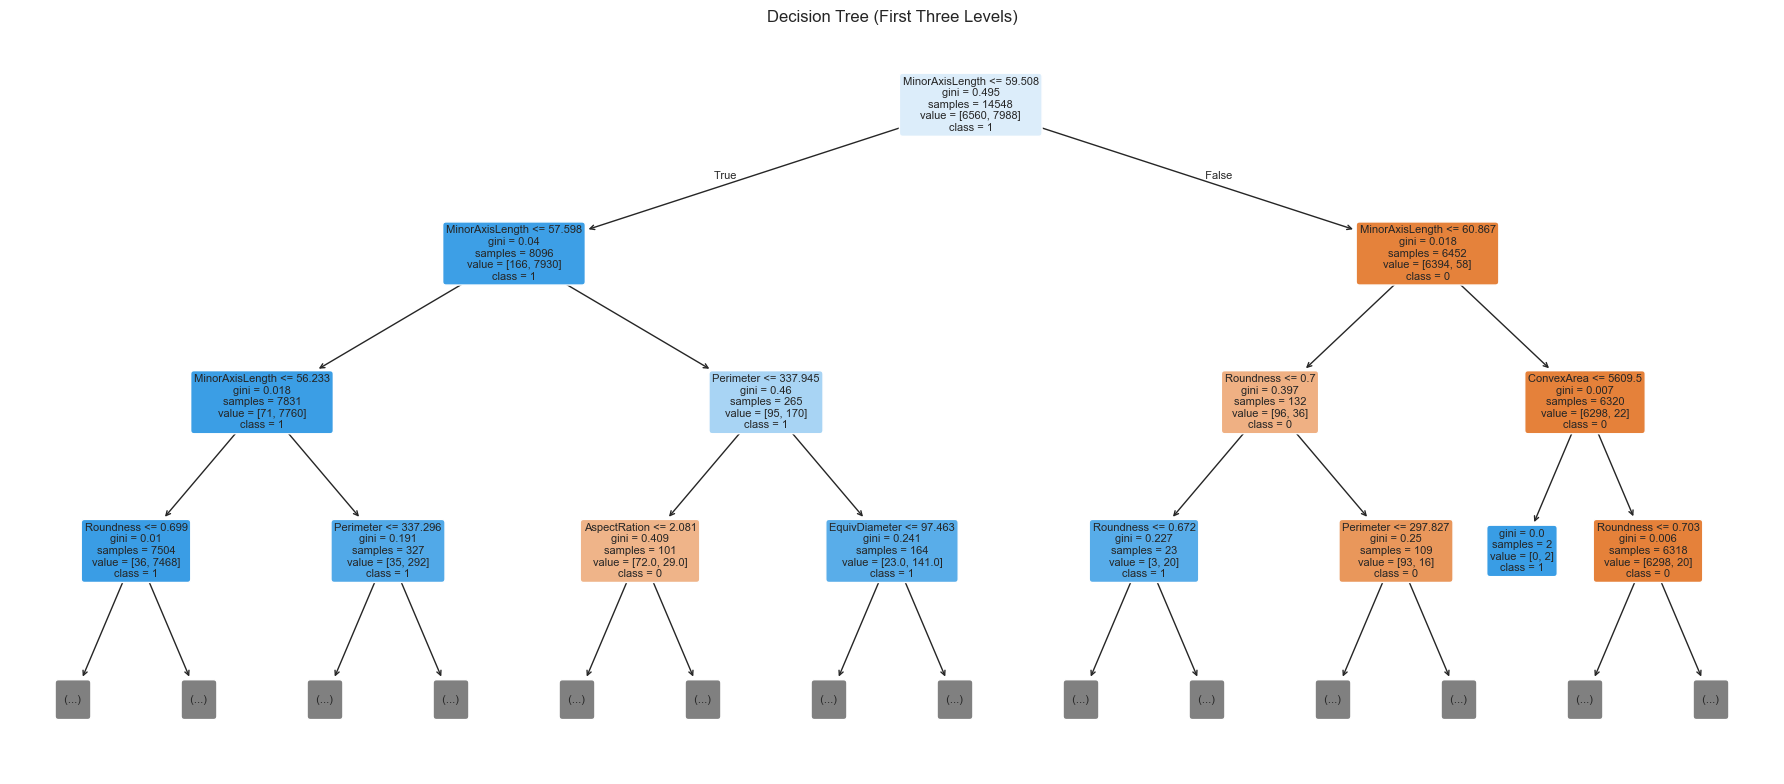

In [58]:
tree_model = models["Decision Tree"].named_steps["classifier"]
plt.figure(figsize=(18, 8))
plot_tree(
    tree_model,
    feature_names=X.columns.tolist(),
    class_names=class_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (First Three Levels)")
plt.tight_layout()
plt.show()

## 21. Final Model Comparison

In [60]:
# Compare all four models using the same held-out test set.
comparison = results_df.sort_values(
    ["F1-score (macro)", "Accuracy"], ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
display(comparison.round(4))

print("Best by accuracy:", results_df.loc[results_df["Accuracy"].idxmax(), "Model"])
print("Best by macro precision:", results_df.loc[results_df["Precision (macro)"].idxmax(), "Model"])
print("Best by macro recall:", results_df.loc[results_df["Recall (macro)"].idxmax(), "Model"])
print("Best by macro F1-score:", results_df.loc[results_df["F1-score (macro)"].idxmax(), "Model"])
print("Best by log loss (lowest):", results_df.loc[results_df["Log Loss"].idxmin(), "Model"])

# Overall selection prioritizes macro F1-score, then accuracy as a tie-breaker.
best_model_row = comparison.iloc[0]
print("\\nOVERALL SELECTED MODEL:", best_model_row["Model"])
print("Selection rule: highest macro F1-score; accuracy breaks ties.")
print("Accuracy:", round(best_model_row["Accuracy"], 4))
print("Macro precision:", round(best_model_row["Precision (macro)"], 4))
print("Macro recall:", round(best_model_row["Recall (macro)"], 4))
print("Macro F1-score:", round(best_model_row["F1-score (macro)"], 4))
print("Log loss:", round(best_model_row["Log Loss"], 4))

# Export comparison table for the practical report.
comparison.to_csv("rice_classification_model_comparison.csv", index=False)
print("\\nSaved comparison table to rice_classification_model_comparison.csv")

FINAL MODEL COMPARISON


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Log Loss
0,SVM,0.9926,0.9928,0.9923,0.9925,0.0314
1,KNN,0.9915,0.9915,0.9913,0.9914,0.0784
2,Decision Tree,0.9843,0.9841,0.9843,0.9842,0.5649
3,Naïve Bayes,0.9780,0.9805,0.9758,0.9777,0.1493


Best by accuracy: SVM
Best by macro precision: SVM
Best by macro recall: SVM
Best by macro F1-score: SVM
Best by log loss (lowest): SVM
\nOVERALL SELECTED MODEL: SVM
Selection rule: highest macro F1-score; accuracy breaks ties.
Accuracy: 0.9926
Macro precision: 0.9928
Macro recall: 0.9923
Macro F1-score: 0.9925
Log loss: 0.0314
\nSaved comparison table to rice_classification_model_comparison.csv
